# AI Equity Portfolio Concentration and Risk Analysis


1. AI Equity Valuation & Portfolio Concentration

Problem: An investor wants exposure to AI growth, but allocating too much to closely related technology companies could create large losses if expectations weaken.
- Companies: Microsoft, Alphabet, Amazon, NVIDIA, Meta and Oracle.
- Decision: Which companies deserve inclusion, and how much should the portfolio allocate to each?
- What we build: Simplified valuations for three companies, risk analysis for all six, and portfolio weights subject to investment limits.
- Methods: DCF valuation, correlations, constrained optimisation and Monte Carlo scenarios.
- Measure success: Compare concentration, maximum drawdown and expected shortfall against an equal-weight portfolio. Assess returns on a separate historical test period.
- Final answer: A proposed allocation, valuation ranges and an explanation of what could cause the investment thesis to fail.
Realistic scope: A hypothetical investment mandate using public company data. Valuation assumptions must be clearly identified.

## Introduction

Investors seeking exposure to artificial intelligence may hold several
technology companies while remaining exposed to common risks. Different
company names do not necessarily provide broad diversification, especially
when their stock returns move together.

This project analyses a hypothetical $1 million portfolio invested in
Amazon, Alphabet, Meta, Microsoft, NVIDIA and Oracle using real historical
market data. It examines whether changing portfolio weights can reduce
risk compared with investing equal amounts in all six companies.

## Objective

Evaluate whether a constrained minimum-variance allocation reduces
volatility and maximum drawdown compared with an equal-weight portfolio,
while assessing the effect on returns and allocation concentration.

## Approach

- Collect adjusted daily stock prices from Yahoo Finance using Python.
- Estimate portfolio weights using returns from 2020–2023.
- Limit each company's allocation to between 5% and 30%.
- Compare both portfolios from 2024 through November 3, 2026.
- Run 5,000 historical-resampling simulations of one trading year.
- Assess returns, volatility, maximum drawdown and concentration.

Both portfolios assume daily rebalancing before trading costs and taxes.
This is an independent educational case study, not an actual managed
portfolio or a forecast of future performance.

In [1]:
portfolio_value = 1_000_000

companies = {
    "MSFT": "Microsoft",
    "GOOGL": "Alphabet",
    "AMZN": "Amazon",
    "NVDA": "NVIDIA",
    "META": "Meta",
    "ORCL": "Oracle"
}

tickers = list(companies.keys())

print(f"Portfolio value: ${portfolio_value:,.0f}")
print(tickers)

Portfolio value: $1,000,000
['MSFT', 'GOOGL', 'AMZN', 'NVDA', 'META', 'ORCL']


In [2]:
%pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
tickers = ["MSFT", "GOOGL", "AMZN", "NVDA", "META", "ORCL"]
data = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-11-04",
    auto_adjust=True
)

prices = data["Close"]

prices.head()

[*********************100%***********************]  6 of 6 completed


Ticker,AMZN,GOOGL,META,MSFT,NVDA,ORCL
Date,,,,,,
2020-01-02,94.900497,67.788948,207.789841,151.544250,5.957138,48.798698
2020-01-03,93.748497,67.434319,206.690384,149.657272,5.861789,48.626827
2020-01-06,95.143997,69.231712,210.583115,150.044113,5.886369,48.880108
2020-01-07,95.343002,69.097977,211.038712,148.676041,5.957633,48.988647
2020-01-08,94.598503,69.589798,213.178223,151.044250,5.968807,49.179443


In [6]:
prices.isna().sum()

Ticker
AMZN     0
GOOGL    0
META     0
MSFT     0
NVDA     0
ORCL     0
dtype: int64

In [7]:
returns = prices.pct_change(fill_method=None).dropna()

returns.head()

Ticker,AMZN,GOOGL,META,MSFT,NVDA,ORCL
Date,,,,,,
2020-01-03,-0.012139,-0.005231,-0.005291,-0.012452,-0.016006,-0.003522
2020-01-06,0.014886,0.026654,0.018834,0.002585,0.004193,0.005209
2020-01-07,0.002092,-0.001932,0.002164,-0.009118,0.012107,0.002221
2020-01-08,-0.007809,0.007118,0.010138,0.015929,0.001876,0.003895
2020-01-09,0.004799,0.010498,0.014311,0.012493,0.010983,0.004619


In [8]:
correlation = returns.corr()

correlation.round(2)

Ticker,AMZN,GOOGL,META,MSFT,NVDA,ORCL
Ticker,,,,,,
AMZN,1.00,0.63,0.59,0.63,0.55,0.33
GOOGL,0.63,1.00,0.57,0.62,0.54,0.35
META,0.59,0.57,1.00,0.56,0.51,0.30
MSFT,0.63,0.62,0.56,1.00,0.62,0.49
NVDA,0.55,0.54,0.51,0.62,1.00,0.43
ORCL,0.33,0.35,0.30,0.49,0.43,1.00


In [9]:
# Give each company an equal share of the portfolio
num_assets = len(returns.columns)

equal_weights = np.repeat(1 / num_assets, num_assets)

equal_weights

array([0.16666667, 0.16666667, 0.16666667, 0.16666667, 0.16666667,
       0.16666667])

In [10]:
# Calculate daily portfolio returns assuming daily rebalancing before costs
portfolio_returns = (returns * equal_weights).sum(axis=1)

portfolio_returns.head()

Date
2020-01-03   -0.009107
2020-01-06    0.012060
2020-01-07    0.001255
2020-01-08    0.005191
2020-01-09    0.009617
dtype: float64

In [12]:
# Compound daily returns to calculate the portfolio's historical value
portfolio_value = 1000000

portfolio_growth = (1 + portfolio_returns).cumprod()

portfolio_values = portfolio_value * portfolio_growth

portfolio_values.head()

Date
2020-01-03    9.908932e+05
2020-01-06    1.002843e+06
2020-01-07    1.004102e+06
2020-01-08    1.009315e+06
2020-01-09    1.019021e+06
dtype: float64

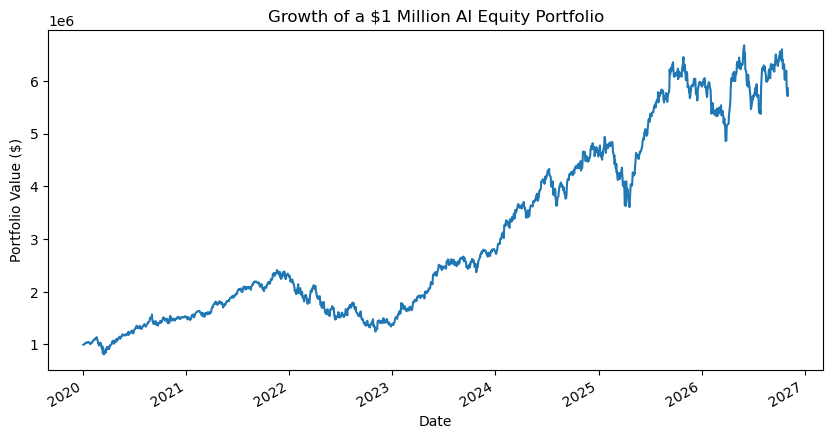

In [13]:
# Plot how the portfolio's value changed over time
portfolio_values.plot(figsize=(10, 5))

plt.title("Growth of a $1 Million AI Equity Portfolio")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")

plt.show()

In [14]:
portfolio_values.iloc[-1]

np.float64(5857648.5783387665)

In [15]:
# Find the portfolio's ending value
total_return = (portfolio_values.iloc[-1] / portfolio_value - 1) * 100

print(total_return)

485.76485783387665


In [16]:
# Measure how much the portfolio's daily returns fluctuate
daily_volatility = portfolio_returns.std()

# Convert daily volatility into an annual estimate
# We assume approximately 252 trading days per year
annual_volatility = daily_volatility * np.sqrt(252)

# Convert the decimal into a percentage and display it
print(annual_volatility * 100)

30.216221773155098


In [17]:
# Measure the portfolio's largest decline from a previous peak
running_peak = portfolio_values.cummax().clip(lower=portfolio_value)

drawdown = (portfolio_values / running_peak) - 1

maximum_drawdown = drawdown.min()

print(maximum_drawdown * 100)

-48.49553756161692


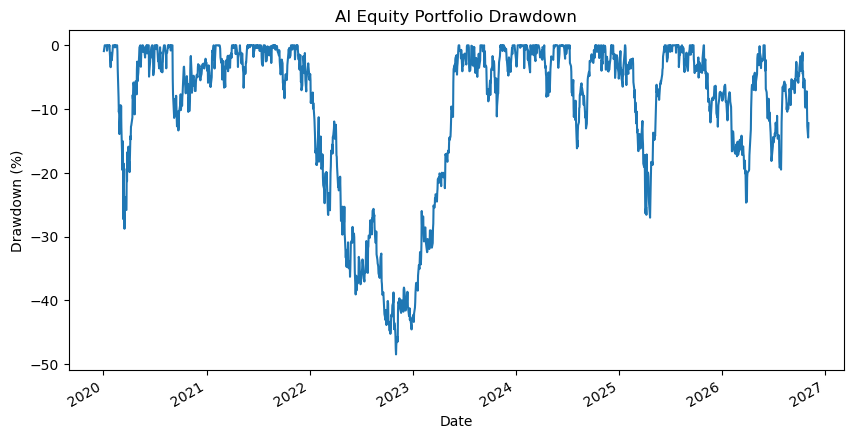

In [18]:
# Show when the portfolio fell below its previous peak
(drawdown * 100).plot(figsize=(10, 5))

plt.title("AI Equity Portfolio Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")

plt.show()

In [19]:
# Find the date of the portfolio's deepest historical decline
worst_drawdown_date = drawdown.idxmin()

print(worst_drawdown_date)

2022-11-03 00:00:00


In [20]:
# Find the portfolio's value on its deepest drawdown date
worst_drawdown_value = portfolio_values.loc[worst_drawdown_date]

print(worst_drawdown_value)

1241033.6472656687


In [21]:
# Find the previous peak used to measure the deepest decline
peak_value = running_peak.loc[worst_drawdown_date]

print(peak_value)

2409565.285241776


In [22]:
# Calculate the dollar loss from the previous peak to the deepest drawdown
drawdown_loss = peak_value - worst_drawdown_value

print(drawdown_loss)

1168531.6379761074


In [23]:
# Compare how much each company's returns fluctuate
stock_volatility = returns.std() * np.sqrt(252) * 100

stock_volatility.sort_values()


Ticker
MSFT     30.262911
GOOGL    32.679363
AMZN     35.599253
ORCL     42.259909
META     43.799984
NVDA     51.522614
dtype: float64

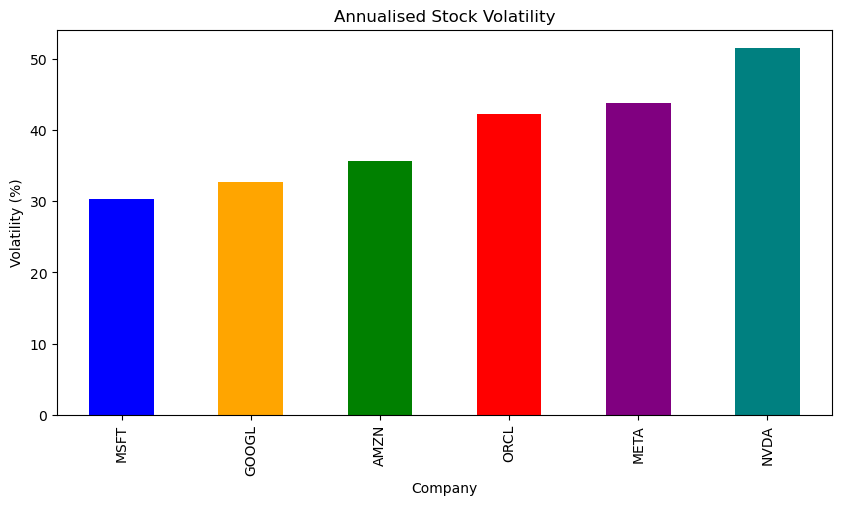

In [25]:
# Give each company's volatility bar a different colour
stock_volatility.sort_values().plot.bar(
    figsize=(10, 5),
    color=["blue", "orange", "green", "red", "purple", "teal"]
)

plt.title("Annualised Stock Volatility")
plt.xlabel("Company")
plt.ylabel("Volatility (%)")

plt.show()

In [26]:
# Separate the data used to choose weights from the data used to test them
train_returns = returns.loc["2020":"2023"]

test_returns = returns.loc["2024":]

print("Training observations:", len(train_returns))
print("Testing observations:", len(test_returns))

Training observations: 1005
Testing observations: 713


In [27]:
# Measure how the stocks' returns vary together using training data
covariance = train_returns.cov()

covariance

Ticker,AMZN,GOOGL,META,MSFT,NVDA,ORCL
Ticker,,,,,,
AMZN,0.000564,0.000333,0.000429,0.000331,0.000493,0.000192
GOOGL,0.000333,0.000446,0.000425,0.000335,0.000470,0.000208
META,0.000429,0.000425,0.000868,0.000380,0.000569,0.000225
MSFT,0.000331,0.000335,0.000380,0.000422,0.000509,0.000245
NVDA,0.000493,0.000470,0.000569,0.000509,0.001167,0.000321
ORCL,0.000192,0.000208,0.000225,0.000245,0.000321,0.000431


In [28]:
# Define how to calculate portfolio variance for any set of weights
def portfolio_variance(weights):
    return weights @ covariance @ weights

In [29]:
# Calculate the equal-weight portfolio's variance using training data
portfolio_variance(equal_weights)

np.float64(0.0004119842827789115)

In [30]:
# Convert training-period portfolio variance into annualised volatility
training_variance = portfolio_variance(equal_weights)

training_volatility = np.sqrt(training_variance) * np.sqrt(252)

print(training_volatility * 100)

32.22111718427617


In [33]:
# Limit each company to between 5% and 30% of the portfolio
bounds = [(0.05, 0.30)] * num_assets

In [36]:
# Require all portfolio weights to add up to 100%
def weight_total(weights):
    return weights.sum() - 1

constraints = {"type": "eq", "fun": weight_total}

In [37]:
# Find portfolio weights that minimise training-period variance
from scipy.optimize import minimize

result = minimize(
    portfolio_variance,
    equal_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"ftol": 0.000000000001}
)

print(result.success)
print(result.message)

True
Optimization terminated successfully


In [38]:
# Display the optimised allocation for each company
optimal_weights = result.x

allocation = pd.Series(optimal_weights, index=train_returns.columns)

print((allocation * 100).round(2))
print("Total weight:", optimal_weights.sum())

Ticker
AMZN     14.27
GOOGL    25.33
META      5.00
MSFT     20.40
NVDA      5.00
ORCL     30.00
dtype: float64
Total weight: 1.0000000000000002


In [40]:
# Calculate both portfolios' daily returns on the unseen test period
equal_test_returns = (test_returns * equal_weights).sum(axis=1)

optimal_test_returns = (test_returns * optimal_weights).sum(axis=1)

In [41]:
# Display both portfolios' daily returns side by side
test_comparison = pd.DataFrame({
    "Equal Weight": equal_test_returns,
    "Optimised": optimal_test_returns
})

test_comparison.head()

,Equal Weight,Optimised
Date,,
2024-01-02,-0.016644,-0.013798
2024-01-03,-0.006351,-0.005661
2024-01-04,-0.005613,-0.008609
2024-01-05,0.006243,0.001581
2024-01-08,0.028416,0.023249


In [42]:
# Compare both portfolios' annualised volatility during the test period
test_volatility = test_comparison.std() * np.sqrt(252) * 100

test_volatility.round(2)

Equal Weight    27.16
Optimised       27.88
dtype: float64

In [43]:
# Compare portfolio values over the same test period from a $1 million starting amount
test_values = portfolio_value * (1 + test_comparison).cumprod()

test_values.tail()

,Equal Weight,Optimised
Date,,
2026-10-28,2.217559e+06,1.966299e+06
2026-10-29,2.146113e+06,1.871599e+06
2026-10-30,2.087155e+06,1.814110e+06
2026-11-02,2.044343e+06,1.757862e+06
2026-11-03,2.097709e+06,1.809416e+06


In [44]:
# Compare each portfolio's largest peak-to-low decline during the test period
test_peaks = test_values.cummax().clip(lower=portfolio_value)

test_drawdowns = (test_values / test_peaks) - 1

test_max_drawdowns = test_drawdowns.min() * 100

test_max_drawdowns.round(2)

Equal Weight   -27.04
Optimised      -28.05
dtype: float64

In [45]:
# Summarise test-period returns and risk for both portfolios
test_total_returns = (test_values.iloc[-1] / portfolio_value - 1) * 100

summary = pd.DataFrame({
    "Ending Value ($)": test_values.iloc[-1],
    "Total Return (%)": test_total_returns,
    "Annual Volatility (%)": test_volatility,
    "Maximum Drawdown (%)": test_max_drawdowns
})

summary.round(2)

,Ending Value ($),Total Return (%),Annual Volatility (%),Maximum Drawdown (%)
Equal Weight,2097708.80,109.77,27.16,-27.04
Optimised,1809415.75,80.94,27.88,-28.05


In [46]:
# Compare how concentrated the portfolio allocations are
weights_table = pd.DataFrame({
    "Equal Weight": equal_weights,
    "Optimised": optimal_weights
}, index=train_returns.columns)

concentration = (weights_table ** 2).sum()

effective_holdings = 1 / concentration

print("Concentration score:")
print(concentration.round(3))

print("Effective number of holdings:")
print(effective_holdings.round(2))

Concentration score:
Equal Weight    0.167
Optimised       0.221
dtype: float64
Effective number of holdings:
Equal Weight    6.00
Optimised       4.52
dtype: float64


In [47]:
# Present concentration measures for both portfolios in one table
concentration_table = pd.DataFrame({
    "Concentration score": concentration,
    "Effective holdings": effective_holdings
}).T

concentration_table.round(3)

,Equal Weight,Optimised
Concentration score,0.167,0.221
Effective holdings,6.000,4.522


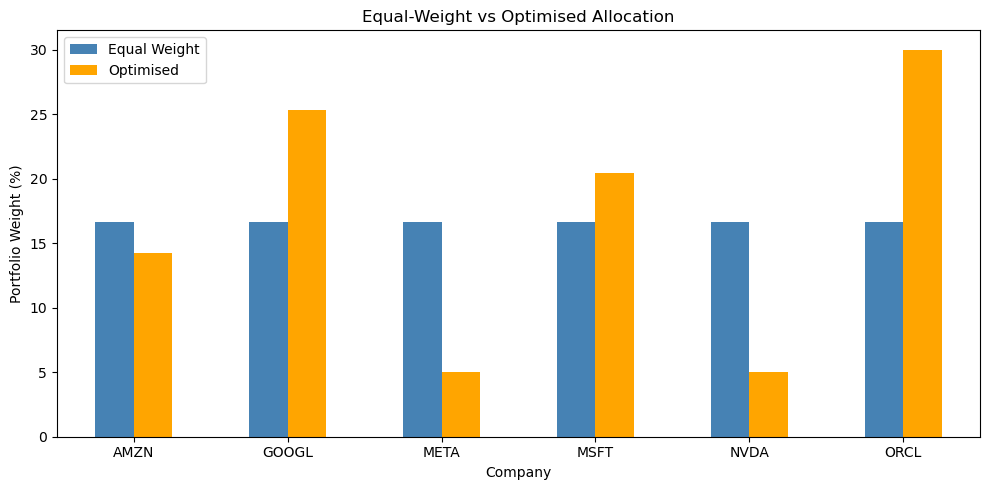

In [48]:
# Show how the investment allocation differs between the two portfolios
(weights_table * 100).plot.bar(
    figsize=(10, 5),
    color=["steelblue", "orange"]
)

plt.title("Equal-Weight vs Optimised Allocation")
plt.xlabel("Company")
plt.ylabel("Portfolio Weight (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [49]:
# Set the number of simulated scenarios and trading days
simulations = 5000
days = 252

rng = np.random.default_rng(42)

In [51]:
# Simulate both portfolios using the same randomly sampled historical days
equal_end_values = []
optimal_end_values = []

for simulation in range(simulations):
    sampled_days = rng.integers(0, len(train_returns), size=days)
    sampled_returns = train_returns.iloc[sampled_days]

    equal_daily = (sampled_returns * equal_weights).sum(axis=1)
    optimal_daily = (sampled_returns * optimal_weights).sum(axis=1)

    equal_end = portfolio_value * (1 + equal_daily).prod()
    optimal_end = portfolio_value * (1 + optimal_daily).prod()

    equal_end_values.append(equal_end)
    optimal_end_values.append(optimal_end)

simulation_results = pd.DataFrame({
    "Equal Weight": equal_end_values,
    "Optimised": optimal_end_values
})

simulation_results.head()

,Equal Weight,Optimised
0,1.475976e+06,1.347947e+06
1,1.163224e+06,1.011080e+06
2,1.724246e+06,1.585096e+06
3,1.123256e+06,1.094979e+06
4,1.926981e+06,1.619899e+06


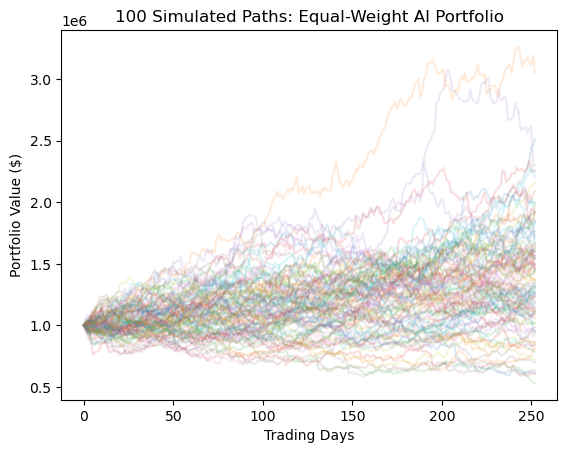

In [52]:
# Show simulated daily portfolio paths over one trading year
plot_rng = np.random.default_rng(42)

for simulation in range(100):
    sampled_days = plot_rng.integers(0, len(train_returns), size=days)
    sampled_returns = train_returns.iloc[sampled_days]

    daily_returns = (sampled_returns * equal_weights).sum(axis=1)

    path = portfolio_value * (1 + daily_returns).cumprod()

    path_values = np.insert(path.to_numpy(), 0, portfolio_value)

    plt.plot(path_values, alpha=0.15)

plt.title("100 Simulated Paths: Equal-Weight AI Portfolio")
plt.xlabel("Trading Days")
plt.ylabel("Portfolio Value ($)")

plt.show()

In [53]:
# Compare simulated downside, typical outcomes and loss frequency
simulation_summary = pd.DataFrame({
    "5th Percentile ($)": simulation_results.quantile(0.05),
    "Median Ending Value ($)": simulation_results.median(),
    "95th Percentile ($)": simulation_results.quantile(0.95),
    "Loss Frequency (%)": (simulation_results < portfolio_value).mean() * 100
})

simulation_summary.round(2)

,5th Percentile ($),Median Ending Value ($),95th Percentile ($),Loss Frequency (%)
Equal Weight,768820.93,1295161.79,2158338.30,21.78
Optimised,785604.13,1239906.37,1981420.81,22.68


In [54]:
# Save the analysis results for reporting and dashboard development
from pathlib import Path

output_folder = Path("../outputs")
output_folder.mkdir(exist_ok=True)

summary.to_csv(output_folder / "test_performance.csv")
weights_table.to_csv(output_folder / "portfolio_weights.csv")
concentration_table.to_csv(output_folder / "concentration.csv")
simulation_summary.to_csv(output_folder / "simulation_summary.csv")
simulation_results.to_csv(output_folder / "simulation_results.csv", index=False)
test_values.to_csv(output_folder / "test_portfolio_values.csv")

print("Files saved in:", output_folder.resolve())

Files saved in: C:\Users\brady\OneDrive\Desktop\AI_Equity_Valuation_Portfolio\outputs


In [55]:
# Save historical prices and daily returns so the analysis can be reproduced
from pathlib import Path

data_folder = Path("../data")
data_folder.mkdir(exist_ok=True)

prices.to_csv(data_folder / "adjusted_prices.csv")
returns.to_csv(data_folder / "daily_returns.csv")

print("Data saved in:", data_folder.resolve())

Data saved in: C:\Users\brady\OneDrive\Desktop\AI_Equity_Valuation_Portfolio\data


## Findings: AI Equity Portfolio Concentration and Risk

### Problem
For a hypothetical $1 million allocation across six AI-exposed companies,
does a constrained minimum-variance portfolio improve risk and performance
compared with equal weighting?

### Method
Analysed Amazon, Alphabet, Meta, Microsoft, NVIDIA and Oracle using
adjusted historical stock prices.

Estimated minimum-variance weights using 2020–2023 returns, with each
holding limited to 5%–30%. Tested the resulting allocation on data from
2024 through November 3, 2026.

Both portfolios assume daily rebalancing before trading costs.

### Test-period results

| Measure | Equal Weight | Optimised |
|---|---:|---:|
| Ending value | $2,097,708.80 | $1,809,415.75 |
| Total return | 109.77% | 80.94% |
| Annualised volatility | 27.16% | 27.88% |
| Maximum drawdown | -27.04% | -28.05% |
| Effective holdings | 6.00 | 4.52 |

### Simulation results
Generated 5,000 one-year scenarios by resampling training-period daily
returns, preserving same-day relationships between the six stocks.

The optimised portfolio had a higher 5th-percentile ending balance
($785,604 versus $769,821), but a lower median ending balance
($1,239,906 versus $1,295,162).

Simulated loss frequencies were 22.68% for the optimised portfolio and
21.78% for equal weighting. These are model-based frequencies, not
known probabilities of future losses.

### Conclusion
The minimum-variance allocation did not improve return, volatility or
maximum drawdown in this test period. It also increased allocation
concentration. This demonstrates that minimising historical variance
does not guarantee lower risk in later periods.

### Limitations
- The six companies were selected with hindsight, creating selection bias.
- All holdings share technology and AI-related exposures.
- Trading costs, taxes and implementation constraints are excluded.
- Weights were estimated once rather than updated through time.
- Daily resampling does not preserve multi-day market trends.
- Historical relationships and simulated outcomes may not persist.
- This analysis does not establish whether the stocks are fairly valued.

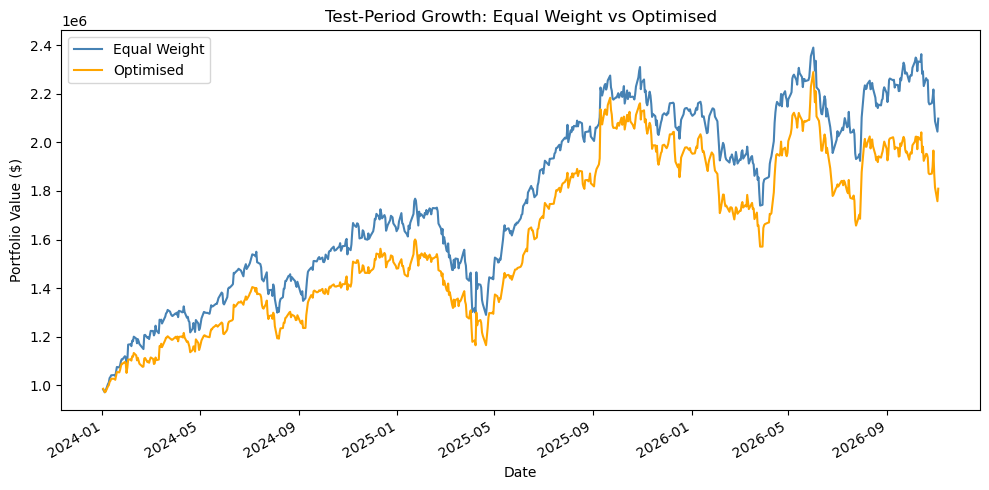

In [56]:
# Compare how both portfolios grew during the test period
test_values.plot(
    figsize=(10, 5),
    color=["steelblue", "orange"]
)

plt.title("Test-Period Growth: Equal Weight vs Optimised")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.tight_layout()

plt.show()